# 06 · SHAP and case studies (RQ3)

Do the attributes the optimizers keep agree with what the model itself relies on?

1. SHAP importance of the tuned all-feature LightGBM on the validation set (T6.1)
2. how often each feature is selected across the 30 optimizer runs, against its SHAP rank, and the H3 verdict (T6.7)
3. three test-set players: a correct star, a missed star and a false alarm (T6.8)

SHAP values are in log-odds: a feature with SHAP value +1 multiplies the odds of "future elite" by e ≈ 2.7 for that player.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import shap
from scipy.stats import spearmanr

from src import config, data, models
from src.features import FEATURES, GROUP_OF, pretty
from src.metrics import pr_auc
from src.final import SHAP_RANKING_FILE, final_feature_sets, tuned_all_feature_model
from src.plotting import AQUA, BLUE, INK_SECONDARY, METHOD_LABEL, MUTED, ORANGE, plt, save, set_style

set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
TABLES = config.RESULTS / "tables"

df = data.load_main()
X_val, y_val = data.get_xy(df, "val")
X_test, y_test = data.get_xy(df, "test")
model = tuned_all_feature_model(df)
explainer = shap.TreeExplainer(model)
names = [pretty(f) for f in FEATURES]
print(f"validation PR-AUC of the model explained here: {pr_auc(y_val, models.scores(model, X_val)):.4f}")

validation PR-AUC of the model explained here: 0.5932


## 1. SHAP importance on the validation set (T6.1)

In [2]:
ex_val = explainer(X_val)
ex_val.feature_names = names
if ex_val.values.ndim == 3:                       # some shap versions return one slice per class
    ex_val = ex_val[..., 1]
ranking = pd.Series(np.abs(ex_val.values).mean(axis=0), index=FEATURES, name="mean |SHAP|").sort_values(ascending=False)
saved = pd.read_csv(SHAP_RANKING_FILE, index_col=0).iloc[:, 0]
assert np.allclose(saved.loc[ranking.index], ranking), "ranking differs from the one used to fix SHAP top-k"
ranking_table = pd.DataFrame({"feature": [pretty(f) for f in ranking.index], "group": [GROUP_OF[f] for f in ranking.index],
                              "mean |SHAP|": ranking.values, "rank": np.arange(1, len(ranking) + 1)}, index=ranking.index)
ranking_table.round(4).to_csv(TABLES / "shap_ranking_val.csv")
ranking_table.head(15).round(4)

,feature,group,mean |SHAP|,rank
age,Age,Profile,0.7004,1
movement_reactions,Reactions,Movement,0.6842,2
skill_fk_accuracy,FK accuracy,Skill,0.3541,3
overall,Overall (current),Rating,0.3539,4
movement_sprint_speed,Sprint speed,Movement,0.3058,5
attacking_short_passing,Short passing,Attacking,0.2923,6
attacking_heading_accuracy,Heading accuracy,Attacking,0.2851,7
height_cm,Height,Profile,0.2784,8
mentality_positioning,Positioning,Mentality,0.2738,9
defending_marking_awareness,Marking awareness,Defending,0.2674,10


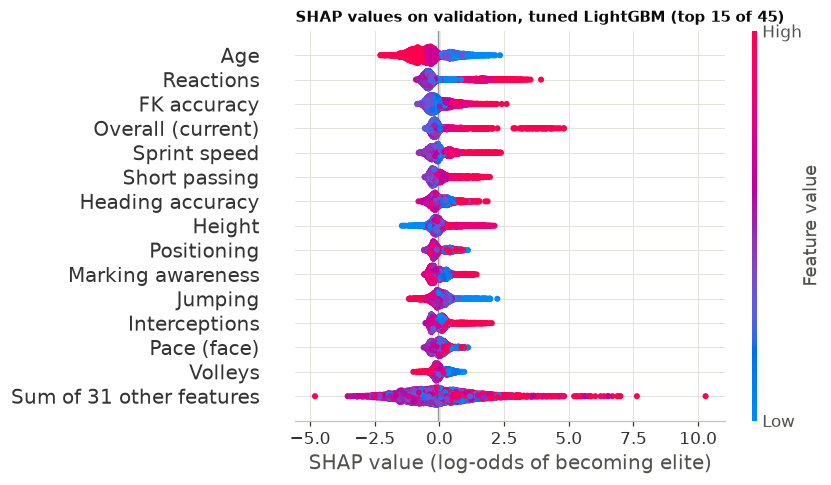

In [3]:
plt.figure()
shap.plots.beeswarm(ex_val, max_display=15, show=False, plot_size=(6.3, 4.6), color_bar_label="Feature value")
fig = plt.gcf()
fig.axes[0].set_title("SHAP values on validation, tuned LightGBM (top 15 of 45)", loc="left", fontsize=10, fontweight="bold")
fig.axes[0].set_xlabel("SHAP value (log-odds of becoming elite)")
save(fig, "fig06a_shap_beeswarm")
plt.show()

## 2. Selection frequency against SHAP rank (T6.7)

30 subsets: the best subset of each of the 10 runs of GA, Binary PSO and Binary GWO at α = 0.99.

In [4]:
counts = pd.DataFrame(0, index=FEATURES, columns=["ga", "bpso", "bgwo"])
for alg in counts.columns:
    for seed in config.RUN_SEEDS:
        summary = json.loads((config.FS_DIR / f"{alg}_seed{seed}.json").read_text())
        counts.loc[summary["best_features"], alg] += 1
counts["total (of 30)"] = counts[["ga", "bpso", "bgwo"]].sum(axis=1)
counts["SHAP rank"] = ranking_table["rank"]
counts["mean |SHAP|"] = ranking_table["mean |SHAP|"]
counts.index = [pretty(f) for f in counts.index]
counts = counts.sort_values("SHAP rank")
counts.to_csv(TABLES / "selection_frequency_vs_shap.csv")

rho, p = spearmanr(counts["mean |SHAP|"], counts["total (of 30)"])
print(f"Spearman correlation between mean |SHAP| and selection count (45 features): rho = {rho:.2f}, p = {p:.3f}")
top10_shap = set(counts.index[:10])
top10_sel = set(counts.sort_values("total (of 30)", ascending=False).index[:10])
print(f"overlap of the SHAP top 10 and the 10 most selected features: {len(top10_shap & top10_sel)} of 10 ->",
      ", ".join(sorted(top10_shap & top10_sel)))
counts.head(15)

Spearman correlation between mean |SHAP| and selection count (45 features): rho = 0.31, p = 0.037
overlap of the SHAP top 10 and the 10 most selected features: 3 of 10 -> Age, Heading accuracy, Height


,ga,bpso,bgwo,total (of 30),SHAP rank,mean |SHAP|
Age,10,10,10,30,1,0.700418
Reactions,1,0,0,1,2,0.684155
FK accuracy,7,4,4,15,3,0.354106
Overall (current),6,3,6,15,4,0.353933
Sprint speed,2,6,2,10,5,0.305763
Short passing,8,6,4,18,6,0.292318
Heading accuracy,9,7,6,22,7,0.285141
Height,10,10,9,29,8,0.278424
Positioning,5,3,3,11,9,0.273823
Marking awareness,1,0,0,1,10,0.267391


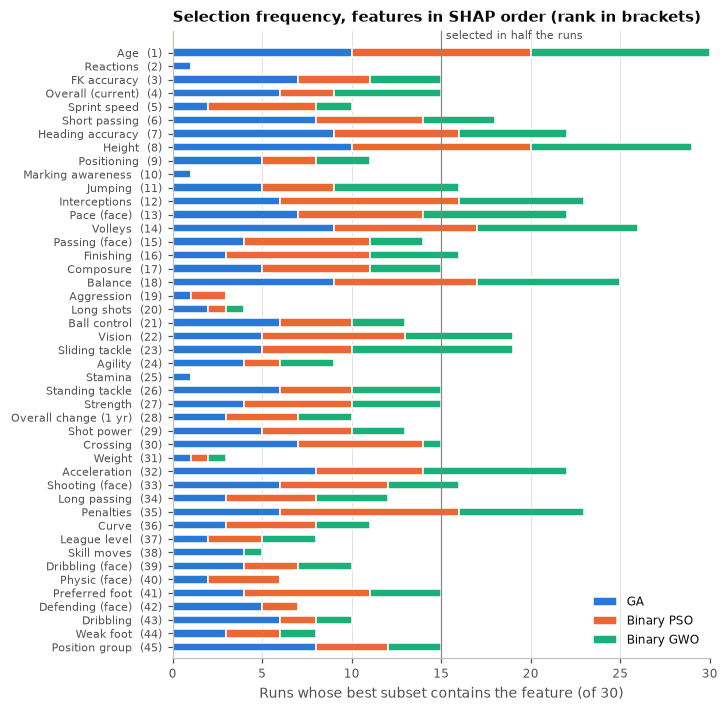

In [5]:
fig, ax = plt.subplots(figsize=(6.3, 7.4))
y = np.arange(len(counts))[::-1]
left = np.zeros(len(counts))
for alg, color in (("ga", BLUE), ("bpso", ORANGE), ("bgwo", AQUA)):
    ax.barh(y, counts[alg], left=left, height=0.62, color=color, edgecolor="white", linewidth=1, label=METHOD_LABEL[alg])
    left += counts[alg].to_numpy()
ax.set_yticks(y, [f"{n}  ({r})" for n, r in zip(counts.index, counts["SHAP rank"])], fontsize=7.5)
ax.axvline(15, color=MUTED, linewidth=0.8)
ax.annotate("selected in half the runs", (15, len(counts) - 0.2), xytext=(3, 0), textcoords="offset points",
            fontsize=7.5, color=INK_SECONDARY, va="bottom")
ax.set(xlabel="Runs whose best subset contains the feature (of 30)", xlim=(0, 30), ylim=(-0.8, len(counts) + 0.6),
       title="Selection frequency, features in SHAP order (rank in brackets)")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
save(fig, "fig06b_selection_vs_shap")
plt.show()

In [6]:
h3 = counts.loc[["Age", "Overall (current)"], ["ga", "bpso", "bgwo", "total (of 30)", "SHAP rank"]]
h3

,ga,bpso,bgwo,total (of 30),SHAP rank
Age,10,10,10,30,1
Overall (current),6,3,6,15,4


Why can a subset drop current overall, or reactions (SHAP rank 2, kept in 1 of 30 runs)? Both are close to redundant once the other attributes are known:

In [7]:
from sklearn.linear_model import LinearRegression
from src.features import DETAILED

train_rows = df[df["set"] == "train"]
val_rows = df[df["set"] == "val"]
others = [f for f in DETAILED if f != "movement_reactions"] + ["position_group"]
fit_overall = LinearRegression().fit(train_rows[others].fillna(train_rows[others].median()), train_rows["overall"])
r2 = fit_overall.score(val_rows[others].fillna(train_rows[others].median()), val_rows["overall"])
print(f"Spearman correlation of reactions with current overall (train rows): {spearmanr(train_rows['movement_reactions'], train_rows['overall'])[0]:.2f}")
print(f"current overall predicted from the other detailed attributes + position group by a linear model: validation R2 = {r2:.3f}")

Spearman correlation of reactions with current overall (train rows): 0.73
current overall predicted from the other detailed attributes + position group by a linear model: validation R2 = 0.817


## 3. Three test-set players (T6.8)

Chosen by rule from the tuned all-feature LightGBM's test scores, so the examples are not cherry-picked:

* **correct star**: the highest-scored player who did become elite;
* **missed star**: the lowest-scored player who did become elite;
* **false alarm**: the highest-scored player who did not.

In [8]:
test = df[df["set"] == "test"].reset_index(drop=True)
test["score"] = models.scores(model, X_test)
test["rank"] = test["score"].rank(ascending=False, method="first").astype(int)
cases = {
    "correct star": test[test["y"] == 1].sort_values("score", ascending=False).index[0],
    "missed star": test[test["y"] == 1].sort_values("score").index[0],
    "false alarm": test[test["y"] == 0].sort_values("score", ascending=False).index[0],
}
cols = ["short_name", "club_name", "league_name", "player_positions", "age", "overall", "potential",
        "overall_t1", "overall_t2", "overall_t3", "score", "rank", "y"]
case_table = test.loc[list(cases.values()), cols].copy()
case_table.index = list(cases.keys())
case_table.to_csv(TABLES / "case_studies.csv")
case_table

,short_name,club_name,league_name,player_positions,age,overall,potential,overall_t1,overall_t2,overall_t3,score,rank,y
correct star,S. Tonali,Milan,Serie A,"CDM, CM",20,77,91,77.0,84.0,86.0,0.993684,1,1.0
missed star,R. Kolo Muani,Nantes,Ligue 1,"ST, RW, LW",21,64,73,74.0,78.0,84.0,0.000004,2412,1.0
false alarm,D. Zagadou,Borussia Dortmund,Bundesliga,CB,21,79,86,78.0,77.0,74.0,0.987898,2,0.0


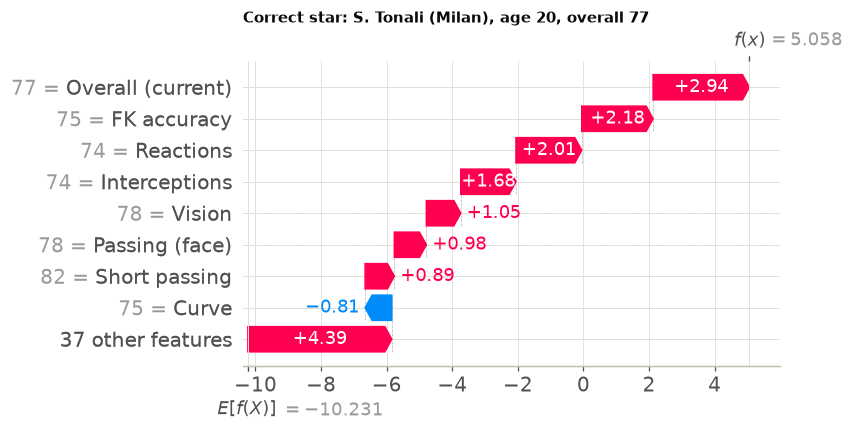

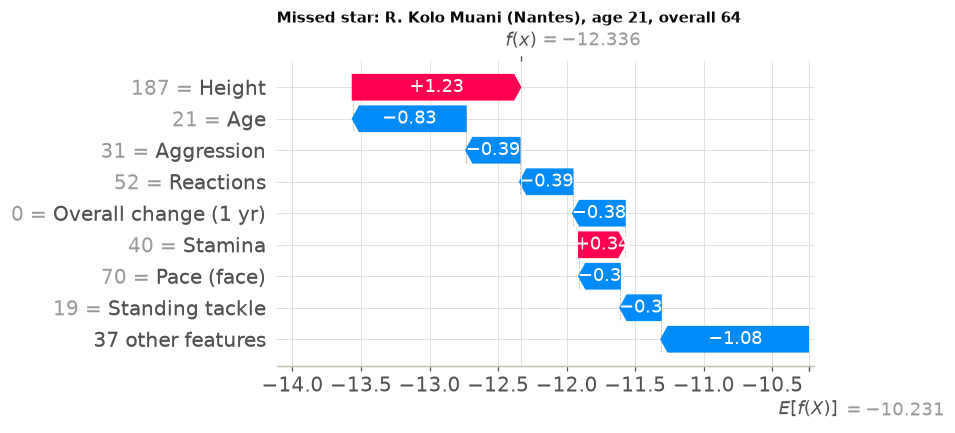

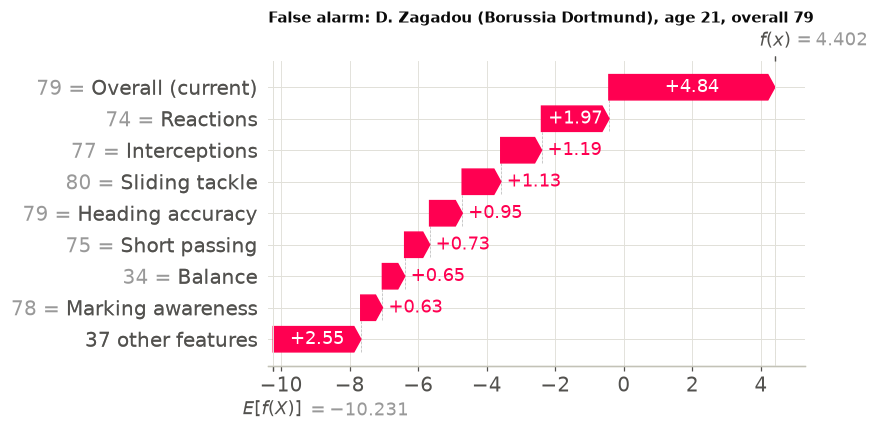

In [9]:
ex_test = explainer(X_test)
ex_test.feature_names = names
if ex_test.values.ndim == 3:
    ex_test = ex_test[..., 1]
for i, (label, idx) in enumerate(cases.items()):
    plt.figure()
    shap.plots.waterfall(ex_test[int(idx)], max_display=9, show=False)
    fig = plt.gcf()
    fig.set_size_inches(6.3, 3.6)
    r = test.loc[idx]
    fig.axes[0].set_title(f"{label.capitalize()}: {r['short_name']} ({r['club_name']}), age {r['age']}, overall {r['overall']}",
                          loc="left", fontsize=10, fontweight="bold")
    save(fig, f"fig06{'cde'[i]}_case_{label.replace(' ', '_')}")
    plt.show()

## 4. Summary

**What the model relies on (T6.1).** On validation, the tuned all-feature LightGBM leans most on age (younger pushes the score up), reactions, free-kick accuracy, current overall and sprint speed. Reactions rises with a player's level (Spearman correlation 0.73 with current overall on the training rows), so the model has two partly overlapping views of the same thing.

**Selection against SHAP (T6.7).** The agreement is weak: the Spearman correlation between mean |SHAP| and selection count is 0.31 (p = 0.037), and only 3 of SHAP's top 10 are among the 10 most selected features (age, heading accuracy, height).
Reactions, SHAP's second feature, was kept in 1 of 30 runs; marking awareness (rank 10) also in 1 of 30.
The two methods answer different questions. SHAP measures how much the full model *uses* a feature; a wrapper keeps a feature only if the other kept features do not already carry its information.
Current overall is largely predictable from the other detailed attributes and position (a linear model explains 82% of its variance on validation), so a subset that keeps enough of them can drop overall, and reactions with it, at little cost.

**H3: partly supported.** Age is kept in all 30 runs, by every optimizer. Current overall is not: only 15 of 30 subsets contain it (GA 6, Binary PSO 3, Binary GWO 6), for the redundancy reason above.
The second half of H3 holds: beyond age, the optimizers agree on few attributes (height 29 of 30, volleys 26, balance 25) and disagree on most of the skill attributes, which is what the low Jaccard similarity in notebook 04 showed.

**Three test-set players (T6.8).**

* **Correct star: Sandro Tonali** (AC Milan, 20, defensive midfielder, overall 77, EA potential 91). Ranked 1st of 3,288 test players. He went 77 → 84 → 86 over the next two versions. The model's reasons are the ones a scout would give: an overall already at 77 (+2.9 log-odds), and free-kick accuracy, reactions, interceptions and vision in the mid-70s for a 20-year-old.
* **Missed star: Randal Kolo Muani** (Nantes, 21, striker, overall 64, potential 73). Ranked 2,412th. He then rose 64 → 74 → 78 → 84 and crossed 80 only in the third version of the window. At 21, rated 64 with no change from the previous year, nothing on his card pointed to that rise; height (187 cm) is the only feature in his favour, and EA's potential of 73 missed him too. This is the late-bloomer failure Feldman (2025) describes: development that happens after the observed card cannot be read from it.
* **False alarm: Dan-Axel Zagadou** (Borussia Dortmund, 21, centre-back, overall 79, potential 86). Ranked 2nd. Instead of reaching 80 he went 78 → 77 → 74. The model's case looked strong: one point below the threshold, with high reactions, interceptions, sliding tackle and heading for his position. Ratings can fall for reasons a game card does not record, such as injuries or lost playing time, and a model built from the card cannot see them.

The base value of the explanations, E[f(X)] = −10.2 log-odds, reflects how rare a future elite player is: almost every test player starts far below the threshold, and the cases above are decided by a handful of attributes.